In [1]:

import torch
import torchvision
import sys

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")
else:
    device = torch.device("cpu")
    print("WARNING: GPU not available!")


Python version: 3.13.16
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 15.64 GB


In [2]:

!pip -q install kaggle


In [3]:

from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle token configured successfully!")


Kaggle token configured successfully!


In [4]:

!pip -q install -U kaggle

!kaggle competitions files -c cifar-10-res-net-architecture-challenge-dl


Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7hsk_Mk0xyzswryQYhVRanVXPgHavhWm--Pj470hTS2EXlkt9LVwPD4gAesXEr48au33so14rxeCDMaIu0DfM15cikKVcgjVfCKrlZmbV2rZMygGFtVdKl9iZvMpdMaqt7u9tel
name                             size  creationDate                
-------------------------  ----------  --------------------------  
sample_submission.csv           12899  2026-10-26 04:09:59.117000  
test.csv                        36902  2026-10-26 04:09:59.112000  
test_images/test_0000.png        2038  2026-10-26 04:09:59.423000  
test_images/test_0001.png        2042  2026-10-26 04:09:59.422000  
test_images/test_0002.png        2230  2026-10-26 04:09:59.422000  
test_images/test_0003.png        2464  2026-10-26 04:09:59.386000  
test_images/test_0004.png        2550  2026-10-26 04:09:59.390000  
test_images/test_0005.png        2118  2026-10-26 04:09:59.425000  
test_images/test_0006.png        2302  2026-10-26 04:09:59.442000  
test_images/test_0007.png        2357  2026-10-26 04:09:59.422000  
test_

In [6]:

from pathlib import Path
import subprocess

DATA_DIR = Path("/content/cifar10_project")
DATA_DIR.mkdir(parents=True, exist_ok=True)

competition = "cifar-10-res-net-architecture-challenge-dl"

result = subprocess.run(
    [
        "kaggle", "competitions", "download",
        "-c", competition,
        "-f", "train_labels.csv",
        "-p", str(DATA_DIR)
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Errors:", result.stderr)

print("Downloaded files:", [p.name for p in DATA_DIR.iterdir()])


Return code: 0
Output: Downloading train_labels.csv to /content/cifar10_project


Errors: 
  0%|          | 0.00/1.18M [00:00<?, ?B/s]
 85%|████████▍ | 1.00M/1.18M [00:01<00:00, 776kB/s]
100%|██████████| 1.18M/1.18M [00:01<00:00, 882kB/s]

Downloaded files: ['train_labels.csv']


In [7]:

from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

competition = "cifar-10-res-net-architecture-challenge-dl"

# Inspect the file listing
files = api.competition_list_files(competition)

print("Files returned:", len(files.files))
print("First five:")
for f in files.files[:5]:
    print(f.name)


Files returned: 20
First five:
sample_submission.csv
test.csv
test_images/test_0000.png
test_images/test_0001.png
test_images/test_0002.png


In [8]:

import inspect

print("API method signature:")
print(inspect.signature(api.competition_list_files))

print("\nPagination details:")
print("Next page token:", bool(files.nextPageToken))
print("Files on first page:", len(files.files))


API method signature:
(competition: str, page_token: Optional[str] = None, page_size: int = 20) -> kagglesdk.competitions.types.competition_api_service.ApiListDataFilesResponse

Pagination details:
Next page token: True
Files on first page: 20


In [9]:

competition = "cifar-10-res-net-architecture-challenge-dl"

all_files = []
page_token = None

while True:
    response = api.competition_list_files(
        competition,
        page_token=page_token,
        page_size=1000
    )

    all_files.extend(response.files)

    print(f"Files discovered: {len(all_files)}")

    page_token = response.nextPageToken

    if not page_token:
        break

print("\nTotal files:", len(all_files))

train_files = [
    f for f in all_files
    if f.name.startswith("train_images/")
]

test_files = [
    f for f in all_files
    if f.name.startswith("test_images/")
]

print("Training images:", len(train_files))
print("Test images:", len(test_files))

print("\nOther files:")
for f in all_files:
    if not f.name.startswith(("train_images/", "test_images/")):
        print(f.name)


Files discovered: 200
Files discovered: 400
Files discovered: 600
Files discovered: 800
Files discovered: 1000
Files discovered: 1200
Files discovered: 1400
Files discovered: 1600
Files discovered: 1800
Files discovered: 2000
Files discovered: 2200
Files discovered: 2400
Files discovered: 2600
Files discovered: 2800
Files discovered: 3000
Files discovered: 3200
Files discovered: 3400
Files discovered: 3600
Files discovered: 3800
Files discovered: 4000
Files discovered: 4200
Files discovered: 4400
Files discovered: 4600
Files discovered: 4800
Files discovered: 5000
Files discovered: 5200
Files discovered: 5400
Files discovered: 5600
Files discovered: 5800
Files discovered: 6000
Files discovered: 6200
Files discovered: 6400
Files discovered: 6600
Files discovered: 6800
Files discovered: 7000
Files discovered: 7200
Files discovered: 7400
Files discovered: 7600
Files discovered: 7800
Files discovered: 8000
Files discovered: 8200
Files discovered: 8400
Files discovered: 8600
Files discovere

HTTPError: 429 Client Error: Too Many Requests for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/ListDataFiles

In [10]:

import time
import requests

print("Already discovered:", len(all_files))
print("Resume token available:", bool(page_token))

while page_token:
    try:
        response = api.competition_list_files(
            competition,
            page_token=page_token,
            page_size=200
        )

        all_files.extend(response.files)
        page_token = response.nextPageToken

        print(f"Files discovered: {len(all_files)}")

        # Slow down requests to avoid rate limits
        time.sleep(2)

    except requests.exceptions.HTTPError as e:
        if e.response is not None and e.response.status_code == 429:
            print("Rate limit reached. Waiting 60 seconds...")
            time.sleep(60)
        else:
            raise

print("\nTotal files discovered:", len(all_files))


Already discovered: 20000
Resume token available: True
Files discovered: 20200
Files discovered: 20400
Files discovered: 20600
Files discovered: 20800
Files discovered: 21000
Files discovered: 21200
Files discovered: 21400
Files discovered: 21600
Files discovered: 21800
Files discovered: 22000
Files discovered: 22200
Files discovered: 22400
Files discovered: 22600
Files discovered: 22800
Files discovered: 23000
Files discovered: 23200
Files discovered: 23400
Files discovered: 23600
Files discovered: 23800
Files discovered: 24000
Files discovered: 24200
Files discovered: 24400
Files discovered: 24600
Files discovered: 24800
Files discovered: 25000
Files discovered: 25200
Files discovered: 25400
Files discovered: 25600
Files discovered: 25800
Files discovered: 26000
Files discovered: 26200
Files discovered: 26400
Files discovered: 26600
Files discovered: 26800
Files discovered: 27000
Files discovered: 27200
Files discovered: 27400
Files discovered: 27600
Files discovered: 27800
Files dis

In [11]:

print("Training images:",
      sum(f.name.startswith("train_images/") for f in all_files))

print("Test images:",
      sum(f.name.startswith("test_images/") for f in all_files))

print("Total files:", len(all_files))


Training images: 50000
Test images: 2000
Total files: 52003


In [12]:

from pathlib import Path

DATA_DIR = Path("/content/cifar10_project")

# Download one training image
api.competition_download_file(
    competition,
    "train_images/train_00000.png",
    path=str(DATA_DIR)
)

print("\nFiles downloaded:")
for p in DATA_DIR.rglob("*"):
    if p.is_file():
        print(p.relative_to(DATA_DIR))
        if len(list(DATA_DIR.rglob("*.png"))) >= 1:
            break


100%|██████████| 2.41k/2.41k [00:00<00:00, 5.06MB/s]



Files downloaded:
train_labels.csv


In [13]:

from pathlib import Path
import time
import requests

DATA_DIR = Path("/content/cifar10_project")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Use the filenames we already collected
image_names = [
    f.name for f in all_files
    if f.name.startswith(("train_images/", "test_images/"))
]

print("Total images:", len(image_names))

downloaded = 0

for filename in image_names[:20]:
    target = DATA_DIR / filename

    if target.exists() and target.stat().st_size > 0:
        print("Already exists:", filename)
        continue

    try:
        api.competition_download_file(
            competition,
            filename,
            path=str(DATA_DIR),
            quiet=True
        )
        downloaded += 1
        print("Downloaded:", filename)
        time.sleep(0.5)

    except Exception as e:
        print("Download failed:", filename, str(e)[:150])
        break

print("\nNew downloads:", downloaded)
print("Images on disk:", len(list(DATA_DIR.rglob("*.png"))))


Total images: 52000
Downloaded: test_images/test_0000.png
Downloaded: test_images/test_0001.png
Downloaded: test_images/test_0002.png
Downloaded: test_images/test_0003.png
Downloaded: test_images/test_0004.png
Downloaded: test_images/test_0005.png
Downloaded: test_images/test_0006.png
Downloaded: test_images/test_0007.png
Downloaded: test_images/test_0008.png
Downloaded: test_images/test_0009.png
Downloaded: test_images/test_0010.png
Downloaded: test_images/test_0011.png
Downloaded: test_images/test_0012.png
Downloaded: test_images/test_0013.png
Downloaded: test_images/test_0014.png
Downloaded: test_images/test_0015.png
Downloaded: test_images/test_0016.png
Downloaded: test_images/test_0017.png
Downloaded: test_images/test_0018.png
Downloaded: test_images/test_0019.png

New downloads: 20
Images on disk: 21


In [14]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/DL - Project 1")

print("Folder exists:", DRIVE_DIR.exists())

if DRIVE_DIR.exists():
    print("\nFiles in Google Drive:")
    for file in DRIVE_DIR.iterdir():
        print(file.name)


Mounted at /content/drive
Folder exists: True

Files in Google Drive:
Train Images.zip
Test Images.zip


In [15]:

import zipfile
from pathlib import Path

DATA_DIR = Path("/content/cifar10_project")
DATA_DIR.mkdir(parents=True, exist_ok=True)

zip_names = ["Train Images.zip", "Test Images.zip"]

for name in zip_names:
    zip_path = DRIVE_DIR / name

    print(f"Extracting {name}...")

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)

    print(f"Finished extracting {name}")

print("\nExtraction complete!")



Extracting Train Images.zip...
Finished extracting Train Images.zip
Extracting Test Images.zip...
Finished extracting Test Images.zip

Extraction complete!


In [16]:

from pathlib import Path

DATA_DIR = Path("/content/cifar10_project")

print("Top-level contents:")
for item in sorted(DATA_DIR.iterdir()):
    print(item.name)

print("\nImage folders and counts:")
for folder in sorted(DATA_DIR.rglob("*")):
    if folder.is_dir():
        count = sum(1 for _ in folder.glob("*.png"))
        if count:
            print(f"{folder.relative_to(DATA_DIR)}: {count} images")

print("\nCSV files:")
for csv_file in DATA_DIR.rglob("*.csv"):
    print(csv_file.relative_to(DATA_DIR))


Streaming output truncated to the last 5000 lines.
train_45009.png
train_45010.png
train_45011.png
train_45012.png
train_45013.png
train_45014.png
train_45015.png
train_45016.png
train_45017.png
train_45018.png
train_45019.png
train_45020.png
train_45021.png
train_45022.png
train_45023.png
train_45024.png
train_45025.png
train_45026.png
train_45027.png
train_45028.png
train_45029.png
train_45030.png
train_45031.png
train_45032.png
train_45033.png
train_45034.png
train_45035.png
train_45036.png
train_45037.png
train_45038.png
train_45039.png
train_45040.png
train_45041.png
train_45042.png
train_45043.png
train_45044.png
train_45045.png
train_45046.png
train_45047.png
train_45048.png
train_45049.png
train_45050.png
train_45051.png
train_45052.png
train_45053.png
train_45054.png
train_45055.png
train_45056.png
train_45057.png
train_45058.png
train_45059.png
train_45060.png
train_45061.png
train_45062.png
train_45063.png
train_45064.png
train_45065.png
train_45066.png
train_45067.png
train

In [17]:

from pathlib import Path

DATA_DIR = Path("/content/cifar10_project")

print("Checking extracted folders:\n")

for folder in DATA_DIR.rglob("*"):
    if folder.is_dir():
        count = sum(1 for f in folder.iterdir() if f.suffix.lower() == ".png")

        if count > 0:
            print("Folder:", folder)
            print("PNG images:", count)
            print("-" * 40)


Checking extracted folders:

Folder: /content/cifar10_project/test_images
PNG images: 20
----------------------------------------
Folder: /content/cifar10_project/train_images
PNG images: 1
----------------------------------------


In [18]:

from pathlib import Path
from collections import Counter
import zipfile

DATA_DIR = Path("/content/cifar10_project")

# Count PNG files directly inside the project folder
root_images = list(DATA_DIR.glob("*.png"))

print("PNG files directly in project folder:", len(root_images))
print("Sample filenames:", [p.name for p in root_images[:5]])

# Inspect the structure of the original ZIP files
for name in ["Train Images.zip", "Test Images.zip"]:
    zip_path = DRIVE_DIR / name

    with zipfile.ZipFile(zip_path, "r") as z:
        png_names = [
            f for f in z.namelist()
            if f.lower().endswith(".png")
        ]

        print(f"\n{name}")
        print("Images inside ZIP:", len(png_names))
        print("First 5 paths:", png_names[:5])


PNG files directly in project folder: 52000
Sample filenames: ['train_08132.png', 'train_43822.png', 'train_01671.png', 'train_19205.png', 'train_48567.png']

Train Images.zip
Images inside ZIP: 50000
First 5 paths: ['train_00000.png', 'train_00001.png', 'train_00002.png', 'train_00003.png', 'train_00004.png']

Test Images.zip
Images inside ZIP: 2000
First 5 paths: ['test_0000.png', 'test_0001.png', 'test_0002.png', 'test_0003.png', 'test_0004.png']


In [19]:

from pathlib import Path
import shutil

DATA_DIR = Path("/content/cifar10_project")

train_dir = DATA_DIR / "train_images"
test_dir = DATA_DIR / "test_images"

train_dir.mkdir(exist_ok=True)
test_dir.mkdir(exist_ok=True)

# Move training images
for image in DATA_DIR.glob("train_*.png"):
    shutil.move(str(image), str(train_dir / image.name))

# Move test images
for image in DATA_DIR.glob("test_*.png"):
    shutil.move(str(image), str(test_dir / image.name))

# Verify
train_count = len(list(train_dir.glob("*.png")))
test_count = len(list(test_dir.glob("*.png")))

print("Training images:", train_count)
print("Test images:", test_count)

assert train_count == 50000, "Training image count is incorrect!"
assert test_count == 2000, "Test image count is incorrect!"

print("\nDataset organization successful!")


Training images: 50000
Test images: 2000

Dataset organization successful!


In [20]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/cifar10_project")

train_df = pd.read_csv(DATA_DIR / "train_labels.csv")

print("Dataset shape:", train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst 10 rows:")
print(train_df.head(10))

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nLabel distribution:")
print(train_df.iloc[:, -1].value_counts().sort_index())


Dataset shape: (50000, 3)

Column names:
['id', 'filename', 'label']

First 10 rows:
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9
3   3  train_00003.png      4
4   4  train_00004.png      1
5   5  train_00005.png      1
6   6  train_00006.png      2
7   7  train_00007.png      7
8   8  train_00008.png      8
9   9  train_00009.png      3

Missing values:
id          0
filename    0
label       0
dtype: int64

Label distribution:
label
0    5000
1    5000
2    5000
3    5000
4    5000
5    5000
6    5000
7    5000
8    5000
9    5000
Name: count, dtype: int64


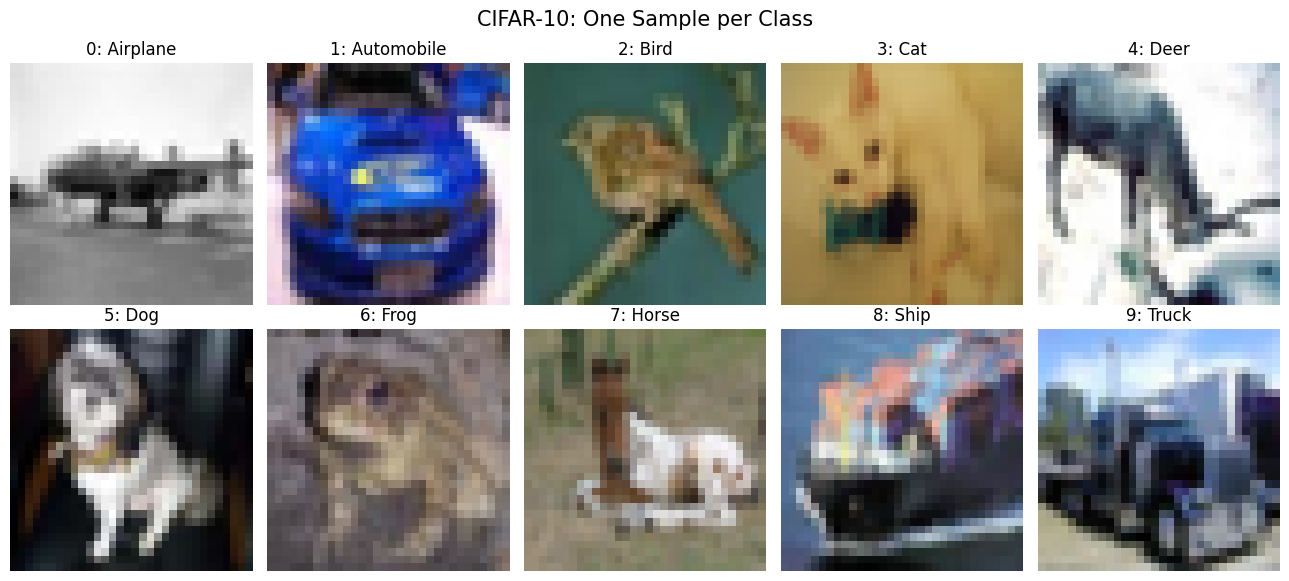

Image dimensions: (32, 32)
Image mode: RGB


In [21]:

import matplotlib.pyplot as plt
from PIL import Image

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Select one image from each class
samples = (
    train_df.groupby("label")
    .sample(n=1, random_state=42)
    .sort_values("label")
)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image_path = DATA_DIR / "train_images" / row["filename"]
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(f"{row['label']}: {class_names[row['label']]}")
    ax.axis("off")

plt.suptitle("CIFAR-10: One Sample per Class", fontsize=15)
plt.tight_layout()
plt.show()

# Verify image dimensions
image = Image.open(
    DATA_DIR / "train_images" / train_df.iloc[0]["filename"]
)

print("Image dimensions:", image.size)
print("Image mode:", image.mode)


In [22]:

from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df,
    test_size=0.10,
    random_state=42,
    stratify=train_df["label"]
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))

print("\nTraining class distribution:")
print(train_data["label"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_data["label"].value_counts().sort_index())

# Ensure there is no overlap
assert set(train_data["id"]).isdisjoint(set(val_data["id"]))

print("\nSplit successful! No overlapping images.")


Training samples: 45000
Validation samples: 5000

Training class distribution:
label
0    4500
1    4500
2    4500
3    4500
4    4500
5    4500
6    4500
7    4500
8    4500
9    4500
Name: count, dtype: int64

Validation class distribution:
label
0    500
1    500
2    500
3    500
4    500
5    500
6    500
7    500
8    500
9    500
Name: count, dtype: int64

Split successful! No overlapping images.


In [23]:

import torch
from torchvision import transforms

# Standard CIFAR-10 normalization statistics
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    transforms.RandomErasing(
        p=0.15,
        scale=(0.02, 0.12),
        ratio=(0.3, 3.3)
    )
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

print("Training transformations:")
print(train_transform)

print("\nValidation transformations:")
print(val_transform)

print("\nTransforms configured successfully!")


Training transformations:
Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
    RandomErasing(p=0.15, scale=(0.02, 0.12), ratio=(0.3, 3.3), value=0, inplace=False)
)

Validation transformations:
Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Transforms configured successfully!


In [24]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

class CIFAR10CustomDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = self.image_dir / row["filename"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = CIFAR10CustomDataset(
    train_data,
    DATA_DIR / "train_images",
    train_transform
)

val_dataset = CIFAR10CustomDataset(
    val_data,
    DATA_DIR / "train_images",
    val_transform
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Test one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape == (128, 3, 32, 32)
assert labels.min() >= 0 and labels.max() <= 9

print("\nDataLoader verification successful!")


Training images: 45000
Validation images: 5000
Training batches: 352
Validation batches: 40

Batch image shape: torch.Size([128, 3, 32, 32])
Batch label shape: torch.Size([128])
Image data type: torch.float32
Label range: 0 to 9

DataLoader verification successful!


In [25]:

import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Match dimensions when channels or resolution change
        self.shortcut = nn.Identity()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        out = self.relu(out)

        return out


# Verify the block
block = ResidualBlock(32, 64, stride=2)

test_input = torch.randn(4, 32, 32, 32)

test_output = block(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", test_output.shape)

assert test_output.shape == (4, 64, 16, 16)

print("\nResidual block verification successful!")


Input shape: torch.Size([4, 32, 32, 32])
Output shape: torch.Size([4, 64, 16, 16])

Residual block verification successful!


In [26]:

import torch
import torch.nn as nn

class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.in_channels = 32

        # Initial convolution for 32x32 CIFAR images
        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 32, kernel_size=3,
                stride=1, padding=1, bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        # Residual stages
        self.layer1 = self._make_layer(64, blocks=3, stride=1)
        self.layer2 = self._make_layer(128, blocks=3, stride=2)
        self.layer3 = self._make_layer(256, blocks=3, stride=2)

        # Classification head
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(256, num_classes)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [
            ResidualBlock(
                self.in_channels, out_channels, stride
            )
        ]

        self.in_channels = out_channels

        for _ in range(1, blocks):
            layers.append(
                ResidualBlock(out_channels, out_channels)
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x


# Create model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CustomResNet(num_classes=10).to(device)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Device:", device)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Parameter limit: {5_000_000:,}")

# Verify architecture using a sample batch
test_input = torch.randn(4, 3, 32, 32).to(device)

model.eval()
with torch.no_grad():
    test_output = model(test_input)

print("\nInput shape:", test_input.shape)
print("Output shape:", test_output.shape)

assert trainable_params <= 5_000_000, \
    "Model exceeds the parameter limit!"

assert test_output.shape == (4, 10), \
    "Incorrect model output shape!"

print("\nCustom ResNet verification successful!")


Device: cuda
Total parameters: 4,310,570
Trainable parameters: 4,310,570
Parameter limit: 5,000,000

Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 10])

Custom ResNet verification successful!


In [27]:

import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# Training configuration
EPOCHS = 60
LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4

# Loss function
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Optimizer
optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=WEIGHT_DECAY,
    nesterov=True
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-5
)

# Save checkpoints to Google Drive
CHECKPOINT_DIR = DRIVE_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_resnet.pth"
LATEST_MODEL_PATH = CHECKPOINT_DIR / "latest_resnet.pth"

# Track training progress
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "learning_rate": []
}

best_val_acc = 0.0

print("Training configuration ready!")
print("Device:", device)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Initial learning rate:", LEARNING_RATE)
print("Optimizer:", type(optimizer).__name__)
print("Scheduler:", type(scheduler).__name__)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Latest checkpoint:", LATEST_MODEL_PATH)


Training configuration ready!
Device: cuda
Epochs: 60
Batch size: 128
Initial learning rate: 0.1
Optimizer: SGD
Scheduler: CosineAnnealingLR
Best checkpoint: /content/drive/MyDrive/DL - Project 1/checkpoints/best_resnet.pth
Latest checkpoint: /content/drive/MyDrive/DL - Project 1/checkpoints/latest_resnet.pth


In [28]:

from tqdm.auto import tqdm
import torch

# Mixed precision for faster GPU training
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Mixed-precision forward pass
        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        # Backpropagation
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Track metrics
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            loss=f"{running_loss / total:.4f}",
            acc=f"{100 * correct / total:.2f}%"
        )

    return running_loss / total, 100 * correct / total


@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, desc="Validation", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            acc=f"{100 * correct / total:.2f}%"
        )

    return running_loss / total, 100 * correct / total


print("Training function ready!")
print("Validation function ready!")
print("Mixed precision enabled:", scaler.is_enabled())


Training function ready!
Validation function ready!
Mixed precision enabled: True


In [29]:

import time
import torch

def run_training(start_epoch=0):
    global best_val_acc

    for epoch in range(start_epoch, EPOCHS):
        start_time = time.time()

        print(f"\nEpoch {epoch + 1}/{EPOCHS}")
        print("-" * 50)

        # Train
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )

        # Validate
        val_loss, val_acc = validate_one_epoch(
            model, val_loader, criterion, device
        )

        current_lr = optimizer.param_groups[0]["lr"]

        # Update learning rate for next epoch
        scheduler.step()

        # Store metrics
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["learning_rate"].append(current_lr)

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc

            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "val_acc": val_acc,
                "train_acc": train_acc
            }, BEST_MODEL_PATH)

            print("New best model saved!")

        # Save latest checkpoint for resuming
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_acc": best_val_acc,
            "history": history
        }, LATEST_MODEL_PATH)

        elapsed = time.time() - start_time

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}%"
        )
        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )
        print(
            f"Learning Rate: {current_lr:.6f} | "
            f"Time: {elapsed:.1f}s"
        )
        print(f"Best Validation Accuracy: {best_val_acc:.2f}%")

    print("\nTraining complete!")
    print(f"Best validation accuracy: {best_val_acc:.2f}%")


print("Main training loop configured successfully!")
print("Ready to start training.")


Main training loop configured successfully!
Ready to start training.


In [30]:

# Run one epoch as an initial test
EPOCHS = 1

run_training(start_epoch=0)



Epoch 1/1
--------------------------------------------------


Training:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

New best model saved!
Train Loss: 2.0110 | Train Acc: 30.34%
Val Loss: 1.7544 | Val Acc: 41.18%
Learning Rate: 0.100000 | Time: 60.2s
Best Validation Accuracy: 41.18%

Training complete!
Best validation accuracy: 41.18%


In [31]:

# Restore the original training duration
EPOCHS = 60

# Load the latest saved checkpoint
checkpoint = torch.load(
    LATEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
scaler.load_state_dict(checkpoint["scaler_state_dict"])

best_val_acc = checkpoint["best_val_acc"]
history = checkpoint["history"]
start_epoch = checkpoint["epoch"]

# Confirm that the cosine scheduler still covers 60 epochs
assert scheduler.T_max == 60, "Scheduler duration is incorrect!"

print("Checkpoint loaded successfully!")
print("Completed epochs:", start_epoch)
print("Remaining epochs:", EPOCHS - start_epoch)
print(f"Best validation accuracy: {best_val_acc:.2f}%")
print("Current learning rate:", optimizer.param_groups[0]["lr"])
print("Scheduler T_max:", scheduler.T_max)
print("Ready to resume training.")


Checkpoint loaded successfully!
Completed epochs: 1
Remaining epochs: 59
Best validation accuracy: 41.18%
Current learning rate: 0.09993148359005492
Scheduler T_max: 60
Ready to resume training.


In [32]:

# Resume training from the saved checkpoint
run_training(start_epoch=start_epoch)



Epoch 2/60
--------------------------------------------------


Training:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

New best model saved!
Train Loss: 1.5747 | Train Acc: 50.36%
Val Loss: 1.4594 | Val Acc: 56.98%
Learning Rate: 0.099931 | Time: 38.6s
Best Validation Accuracy: 56.98%

Epoch 3/60
--------------------------------------------------


Training:   0%|          | 0/352 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78946c551d00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     if w.is_alive():<function _MultiProcessingDataLoaderIter.__del__ at 0x78946c551d00>

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'    
AssertionErrorself._shutdown_workers(): 
can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    if w.is_alive():
  File "/usr/lib/

... (229 outputs left out)

Training:   0%|          | 0/352 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78946c551d00>
Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x78946c551d00>    self._shutdown_workers()
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Train Loss: 0.5105 | Train Acc: 99.78%
Val Loss: 0.6336 | Val Acc: 94.80%
Learning Rate: 0.000079 | Time: 42.7s
Best Validation Accuracy: 94.88%

Training complete!
Best validation accuracy: 94.88%


In [33]:

import torch

# Load best-performing checkpoint
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded successfully!")
print("Saved at epoch:", best_checkpoint["epoch"])
print(f"Saved validation accuracy: {best_checkpoint['val_acc']:.2f}%")

# Re-evaluate on validation dataset
val_loss, val_acc = validate_one_epoch(
    model, val_loader, criterion, device
)

print(f"\nVerified validation loss: {val_loss:.4f}")
print(f"Verified validation accuracy: {val_acc:.2f}%")

assert abs(val_acc - best_checkpoint["val_acc"]) < 0.01, \
    "Validation accuracy does not match saved checkpoint!"

print("\nBest model verification successful!")


Best checkpoint loaded successfully!
Saved at epoch: 55
Saved validation accuracy: 94.88%


Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78946c551d00>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x78946c551d00>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():self._shutdown_workers()
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
:     can only test a child processif w.is_alive():

  File "/usr/lib/


Verified validation loss: 0.6374
Verified validation accuracy: 94.88%

Best model verification successful!


In [34]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path
import pandas as pd

TEST_DIR = DATA_DIR / "test_images"

# Create a sorted list of test filenames
test_files = sorted(TEST_DIR.glob("test_*.png"))

class CIFAR10TestDataset(Dataset):
    def __init__(self, image_files, transform):
        self.image_files = image_files
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_path = self.image_files[idx]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return image


test_dataset = CIFAR10TestDataset(
    test_files,
    val_transform
)

# Avoid multiprocessing warnings during inference
test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("First 5 filenames:", [p.name for p in test_files[:5]])
print("Last 5 filenames:", [p.name for p in test_files[-5:]])

# Verify one batch
test_batch = next(iter(test_loader))
print("\nTest batch shape:", test_batch.shape)

assert len(test_dataset) == 2000
assert test_batch.shape == (128, 3, 32, 32)

print("\nTest DataLoader verification successful!")


Test images: 2000
Test batches: 16
First 5 filenames: ['test_0000.png', 'test_0001.png', 'test_0002.png', 'test_0003.png', 'test_0004.png']
Last 5 filenames: ['test_1995.png', 'test_1996.png', 'test_1997.png', 'test_1998.png', 'test_1999.png']

Test batch shape: torch.Size([128, 3, 32, 32])

Test DataLoader verification successful!


In [35]:

import torch
import numpy as np
from tqdm.auto import tqdm

model.eval()

all_predictions = []

with torch.inference_mode():
    for images in tqdm(test_loader, desc="Predicting test images"):
        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().tolist()
        )

print("\nTotal predictions:", len(all_predictions))
print("First 20 predictions:", all_predictions[:20])

unique, counts = np.unique(
    all_predictions, return_counts=True
)

print("\nPredicted class distribution:")
for label, count in zip(unique, counts):
    print(f"{label} ({class_names[label]}): {count}")

assert len(all_predictions) == 2000
assert all(0 <= p <= 9 for p in all_predictions)

print("\nTest predictions generated successfully!")


Predicting test images:   0%|          | 0/16 [00:00<?, ?it/s]


Total predictions: 2000
First 20 predictions: [6, 3, 3, 9, 3, 2, 8, 4, 8, 8, 3, 1, 9, 8, 3, 6, 7, 9, 6, 1]

Predicted class distribution:
0 (Airplane): 176
1 (Automobile): 217
2 (Bird): 215
3 (Cat): 218
4 (Deer): 184
5 (Dog): 216
6 (Frog): 181
7 (Horse): 189
8 (Ship): 202
9 (Truck): 202

Test predictions generated successfully!


In [36]:

import pandas as pd
from pathlib import Path

# Build submission using actual image filenames
submission_df = pd.DataFrame({
    "id": [int(p.stem.split("_")[1]) for p in test_files],
    "label": all_predictions
})

submission_df = submission_df.sort_values("id").reset_index(drop=True)

# Verify submission
assert len(submission_df) == 2000
assert submission_df["id"].is_unique
assert set(submission_df["id"]) == set(range(2000))
assert submission_df["label"].between(0, 9).all()

print("Submission shape:", submission_df.shape)
print("\nFirst 10 rows:")
print(submission_df.head(10))

print("\nLast 5 rows:")
print(submission_df.tail(5))

# Save locally and to Google Drive
SUBMISSION_PATH = DATA_DIR / "submission.csv"
DRIVE_SUBMISSION_PATH = DRIVE_DIR / "submission.csv"

submission_df.to_csv(SUBMISSION_PATH, index=False)
submission_df.to_csv(DRIVE_SUBMISSION_PATH, index=False)

print("\nSubmission saved successfully!")
print("Colab path:", SUBMISSION_PATH)
print("Google Drive path:", DRIVE_SUBMISSION_PATH)


Submission shape: (2000, 2)

First 10 rows:
   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3
5   5      2
6   6      8
7   7      4
8   8      8
9   9      8

Last 5 rows:
        id  label
1995  1995      7
1996  1996      4
1997  1997      2
1998  1998      5
1999  1999      9

Submission saved successfully!
Colab path: /content/cifar10_project/submission.csv
Google Drive path: /content/drive/MyDrive/DL - Project 1/submission.csv


In [37]:

import pandas as pd
import subprocess
from pathlib import Path

# Download official sample submission
result = subprocess.run(
    [
        "kaggle", "competitions", "download",
        "-c", "cifar-10-res-net-architecture-challenge-dl",
        "-f", "sample_submission.csv",
        "-p", str(DATA_DIR)
    ],
    capture_output=True,
    text=True
)

print("Download result:", result.stdout or result.stderr)

sample_path = DATA_DIR / "sample_submission.csv"

assert sample_path.exists(), "Sample submission not found!"

sample_df = pd.read_csv(sample_path)

print("\nOfficial sample columns:", sample_df.columns.tolist())
print("Our submission columns:", submission_df.columns.tolist())

print("\nOfficial sample:")
print(sample_df.head())

print("\nOur submission:")
print(submission_df.head())

# Verify columns, row count, and ID order
assert sample_df.columns.tolist() == submission_df.columns.tolist()
assert len(sample_df) == len(submission_df)
assert sample_df["id"].astype(str).tolist() == submission_df["id"].astype(str).tolist()

print("\nSubmission format verified successfully!")


Download result: Downloading sample_submission.csv to /content/cifar10_project



Official sample columns: ['id', 'label']
Our submission columns: ['id', 'label']

Official sample:
   id  label
0   0      0
1   1      0
2   2      0
3   3      0
4   4      0

Our submission:
   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3

Submission format verified successfully!


In [38]:

import subprocess

competition = "cifar-10-res-net-architecture-challenge-dl"

result = subprocess.run(
    [
        "kaggle", "competitions", "submit",
        "-c", competition,
        "-f", str(SUBMISSION_PATH),
        "-m", "Custom ResNet 4.31M params - 94.88% validation accuracy"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nKaggle response:")
print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("\nSubmission uploaded successfully!")
else:
    print("\nSubmission was not confirmed. Check the response above.")


Return code: 0

Kaggle response:
Submission ref: 57852194
4 submissions remaining today.
Successfully submitted to NYU Tandon Deep Learning F26 

  0%|          | 0.00/12.6k [00:00<?, ?B/s]
100%|██████████| 12.6k/12.6k [00:01<00:00, 8.00kB/s]


Submission uploaded successfully!
